**Prior 50%Noise only 50%(Noise + Erathquake)**

In [1]:
import sys
sys.path.append("..")

In [ ]:
import h5py
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from ddpm.data.das_dataset import DasDataset
from torch.utils.data import DataLoader, ConcatDataset, Subset
from tqdm.notebook import tqdm
from ddpm.diffusion.noise_scheduler import LinearNoiseScheduler 
from IPython.display import clear_output
from ddpm.utils.normalizer import denormalize
from ddpm.data.wrapper import Source

In [3]:
das_data = Path("/datasets/training/earthquake/share/SISSLE_south30")
train_set_1001 = DasDataset([das_data/"train_1001.h5"])
train_set_1000 = DasDataset([das_data/"train_1000.h5"])

test_set_1001 = DasDataset([das_data/"test_1001.h5"])
test_set_1000 = DasDataset([das_data/"test_1000.h5"])

device = "cuda" if torch.cuda.is_available() else "cpu"

In [4]:
total_train_patches = 16384
e90 = int(total_train_patches * 0.50)
n10 = total_train_patches - e90
print(e90, n10)

8192 8192


In [5]:
total_val_patches = 512
e90v = int(total_val_patches * 0.50)
n10v = total_val_patches - e90v
print(e90v, n10v)

256 256


In [6]:
seed = torch.Generator().manual_seed(42)
i_n = torch.randperm(len(train_set_1000), generator=seed)[:n10]
i_e = torch.randperm(len(train_set_1001), generator=seed)[:e90]
subset_noise = Subset(train_set_1000, i_n)
subset_noise = Source(subset_noise, source=0)
subset_earthquake = Subset(train_set_1001, i_e)
subset_earthquake = Source(subset_earthquake, source=1)
train_set_mix = ConcatDataset([subset_noise, subset_earthquake])

In [7]:
seed_v = torch.Generator().manual_seed(42)
i_nv = torch.randperm(len(test_set_1000), generator=seed_v)[:n10v]
i_ev = torch.randperm(len(test_set_1001), generator=seed_v)[:e90v]
subset_noise_v = Subset(test_set_1000, i_nv)
subset_noise_v = Source(subset_noise_v, source=0)
subset_earthquake_v = Subset(test_set_1001, i_ev)
subset_earthquake_v = Source(subset_earthquake_v, source=1)
test_set_mix= ConcatDataset([subset_noise_v, subset_earthquake_v])

In [8]:
train_loader_mix = DataLoader(train_set_mix, batch_size=16 , shuffle=True)
print("total:", len(train_set_mix), "N+E:", len(subset_earthquake), "N:", len(subset_noise), "batches:" , len(train_loader_mix))

total: 16384 N+E: 8192 N: 8192 batches: 1024


In [9]:
test_loader_mix = DataLoader(test_set_mix, batch_size=16 , shuffle=False)
print("total:", len(test_set_mix), "N+E:", len(subset_earthquake_v), "N:", len(subset_noise_v), "batches:" , len(test_loader_mix))

total: 512 N+E: 256 N: 256 batches: 32


In [ ]:
from ddpm.models.unet_mamba import DDPM
model_mb=  DDPM(in_channels=1, out_channels=1, base_channels=64, channels_multiplier=(1,1,2,2,4),
                  nbr_rb=2, dropout=0.1).to(device)
scheduler_E = LinearNoiseScheduler(timesteps=1000, beta_start=1e-4,beta_end=0.02, device=device)

In [11]:
earthquake_scores = np.load("data/earthquake_unshifted_tail_scores.npy")
strong = np.percentile(earthquake_scores,85)
extreme = np.percentile(earthquake_scores,98)
print("strong: " , strong)
print("extreme:", extreme)

strong:  3237.0437499999994
extreme: 9132.407167968751


In [27]:
import os
print(os.getpid())

1485187


In [12]:
checkpoints=Path("checkpoints")
checkpoints.mkdir(exist_ok=True)
model_mb_path=checkpoints/"das_ddpm_earthquake_model_mamba_weighted_1.2_1.8_mixed_50_50.pth"
model_mb_loss_plot_path=checkpoints/"das_ddpm_earthquake_loss_mamba_weighted_1.2_1.8_mixed_50_50.png"

optimizer_model_mb= torch.optim.Adam(model_mb.parameters(), lr=1e-4)

epochs_earthquake= 20 
earthquake_train_losses=[]
earthquake_val_losses = []
earthquake_start_epoch=0


if model_mb_path.exists():
    checkpoint = torch.load(model_mb_path,map_location=device)
    if "model_mb" in checkpoint:
        model_mb.load_state_dict(checkpoint["model_mb"])
    if "optimizer_model_mb" in checkpoint:
        optimizer_model_mb.load_state_dict(checkpoint["optimizer_model_mb"])
    earthquake_train_losses= checkpoint.get("earthquake_train_losses", [])
    earthquake_val_losses= checkpoint.get("earthquake_val_losses", [])
    earthquake_start_epoch=checkpoint.get("completed_epochs", len(earthquake_train_losses)) 

for epoch in range(earthquake_start_epoch, epochs_earthquake):

    model_mb.train()
    epoch_loss= 0.0

    for batch, source in tqdm(train_loader_mix, desc=f"Epoch{epoch+1}/{epochs_earthquake}"):

        x=batch.to(device)
        source = source.to(device)
        epsilon=torch.randn_like(x)
        t=torch.randint(0,scheduler_E.betas.shape[0],(x.shape[0],),device=device).long()
        xt=scheduler_E.add_noise(x0=x, epsilon=epsilon,t=t)
        noise_prediction=model_mb(xt,t)
        
        loss_sample=((noise_prediction -epsilon)**2).flatten(1).mean(dim=1)

        with torch.no_grad():
            x_denorm = denormalize(x)
            batch_tail_scores = torch.quantile(x_denorm.abs().flatten(1),0.999, dim=1)
            weights = torch.ones_like(batch_tail_scores)
            earthquake_samples = source ==1
            weights[earthquake_samples & (batch_tail_scores >= strong)] = 1.2
            weights[earthquake_samples & (batch_tail_scores >= extreme)] = 1.8

        loss = (weights * loss_sample).sum() / weights.sum()

        optimizer_model_mb.zero_grad()
        loss.backward()
        optimizer_model_mb.step()
        epoch_loss+= loss.item()

    avg_train_loss=epoch_loss/len(train_loader_mix)
    earthquake_train_losses.append(avg_train_loss)

    #validation
    model_mb.eval()
    val_epoch_loss = 0.0
    val_seed = torch.Generator(device=device).manual_seed(42)

    with torch.no_grad():
        for batch, source_v in test_loader_mix:
            x_v = batch.to(device)
            source_v = source_v.to(device)
            epsilon_v = torch.randn(x_v.shape, device=device, generator=val_seed)
            t_v = torch.randint(0,scheduler_E.betas.shape[0],(x_v.shape[0],),device=device, generator=val_seed).long()
            xt_v=scheduler_E.add_noise(x0=x_v, epsilon=epsilon_v,t=t_v)
            noise_prediction_v = model_mb(xt_v,t_v)

            loss_sample_v=((noise_prediction_v - epsilon_v)**2).flatten(1).mean(dim=1)
            
            x_denorm_v = denormalize(x_v)
            batch_tail_scores_v = torch.quantile(x_denorm_v.abs().flatten(1),0.999, dim=1)
            weights_v = torch.ones_like(batch_tail_scores_v)
            earthquake_samples_v = source_v ==1
            weights_v[earthquake_samples_v & (batch_tail_scores_v >= strong)] = 1.2
            weights_v[earthquake_samples_v & (batch_tail_scores_v >= extreme)] = 1.8
            loss_v = (weights_v * loss_sample_v).sum() / weights_v.sum()
            val_epoch_loss += loss_v.item()

    avg_val_loss = (val_epoch_loss / len(test_loader_mix))
    earthquake_val_losses.append(avg_val_loss)

    torch.save({
    "model_mb": model_mb.state_dict(), "optimizer_model_mb": optimizer_model_mb.state_dict(),"strong_weight": 1.2, "extreme_weight": 1.8,"earthquake_train_losses":earthquake_train_losses,
    "earthquake_val_losses": earthquake_val_losses,"loader": "mixed_50_90", "completed_epochs": epoch+1, "base_channels": 64, "channels_multipilier": ( 1,1,2,2,4),
                  "normalizartion": {"function": "arcsinh", "s": 50.0, "A_max": 12350.0}
     }, model_mb_path)
    
    clear_output(wait =  True)
    plt.figure(figsize = (6,4))
    plt.plot(range(1,len(earthquake_train_losses)+1), earthquake_train_losses, marker="o", label = "Training Loss")
    plt.plot(range(1,len(earthquake_val_losses)+1), earthquake_val_losses, marker="o", label = "Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Weighted Noise Prediction Loss")
    plt.title("DDPM Mamba 50/50 Prior - weighted MSE on N+E patches (1.2/1.8)")
    plt.legend()
    plt.savefig(model_mb_loss_plot_path)
    plt.show()

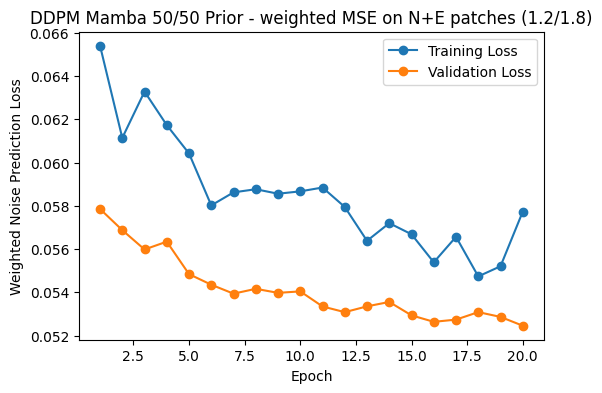

In [15]:
checkpoints=Path("checkpoints")
model_mb_path= Path(checkpoints)/"das_ddpm_earthquake_model_mamba_weighted_1.2_1.8_mixed_50_50.pth"
checkpoint_model_mb = torch.load(model_mb_path, map_location = device)
model_mb.load_state_dict(checkpoint_model_mb["model_mb"])
earthquake_train_losses = checkpoint_model_mb["earthquake_train_losses"]
earthquake_val_losses =  checkpoint_model_mb["earthquake_val_losses"]
plt.figure(figsize = (6,4))
plt.plot(range(1,len(earthquake_train_losses)+1), earthquake_train_losses, marker="o", label = "Training Loss")
plt.plot(range(1,len(earthquake_val_losses)+1), earthquake_val_losses, marker="o", label = "Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Weighted Noise Prediction Loss")
plt.title("DDPM Mamba 50/50 Prior - weighted MSE on N+E patches (1.2/1.8)")
plt.legend()
plt.show()
model_mb = model_mb.to(device)

In [13]:
num_images = 2
xt = torch.randn(num_images, 1,256,512, device = device)
print(xt.shape)
timesteps_shown = [999, 600 , 300, 100, 0]

torch.Size([2, 1, 256, 512])


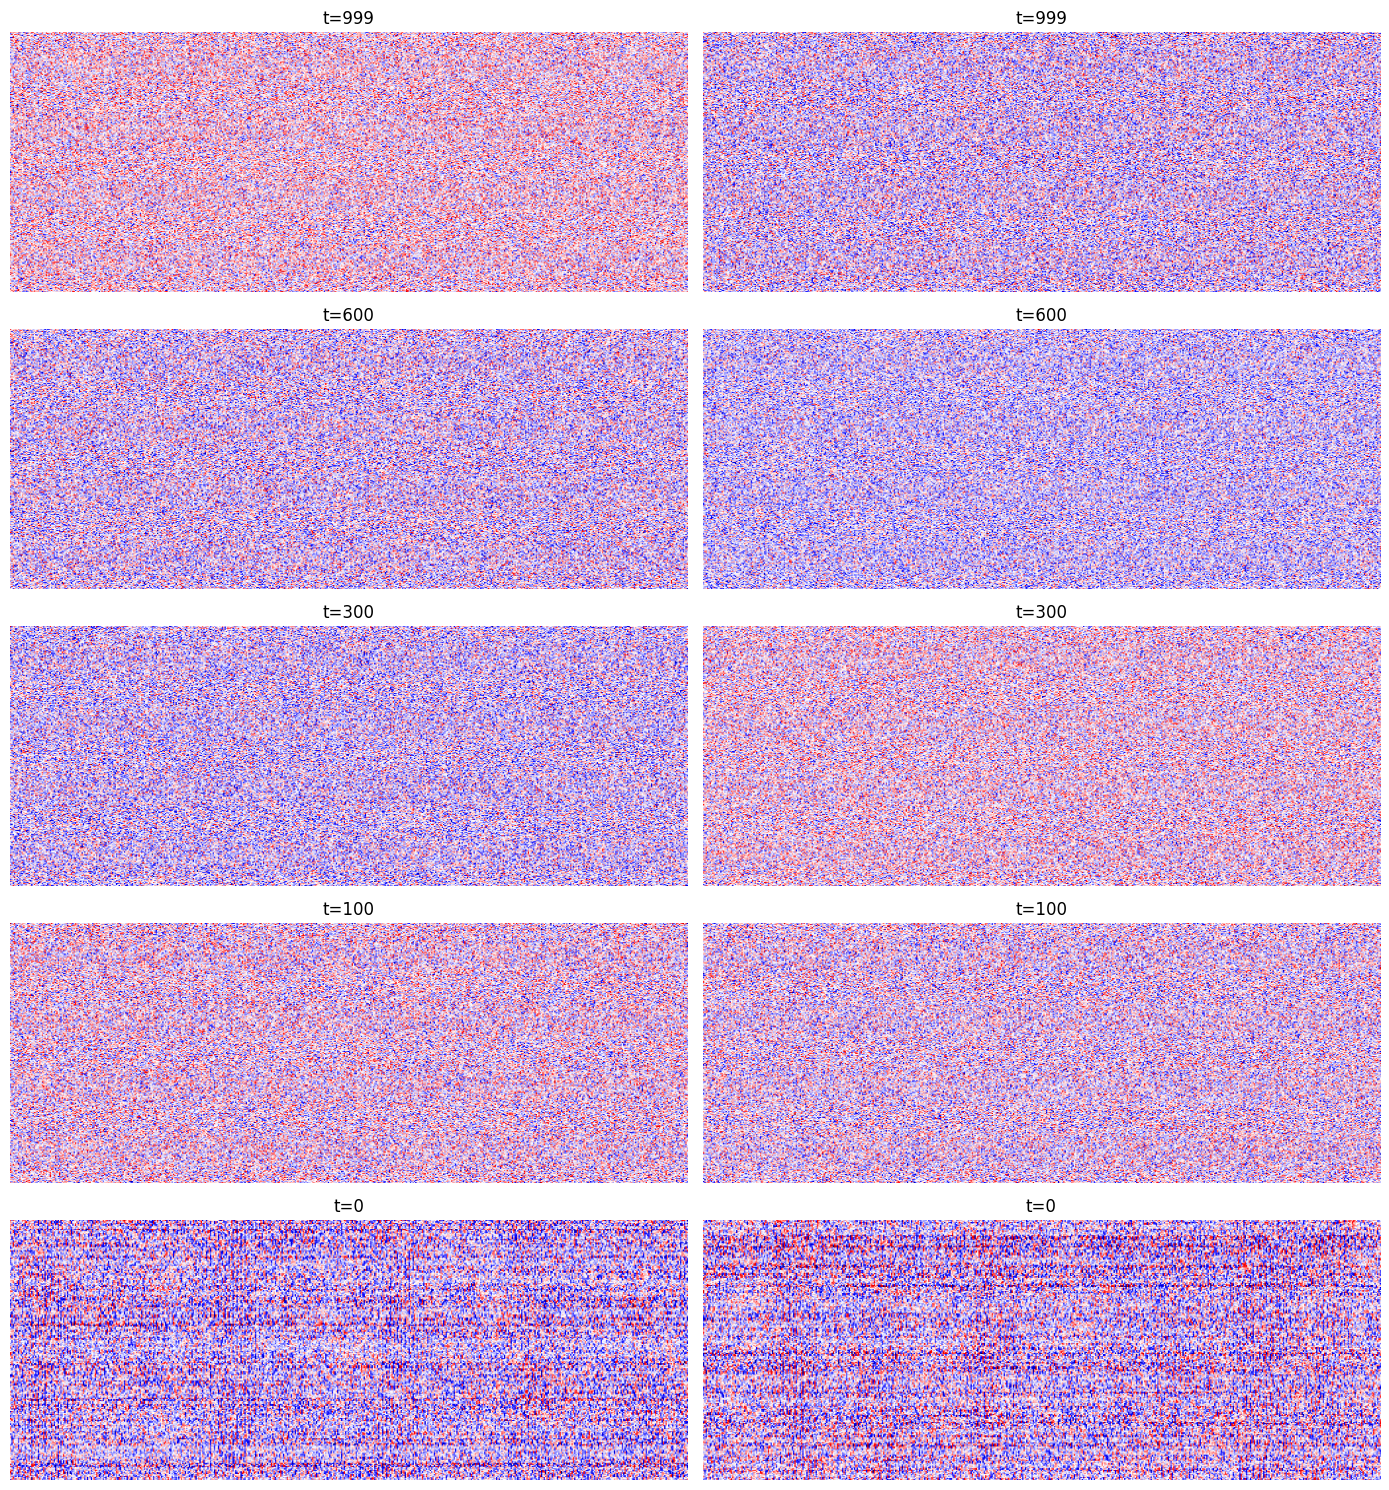

In [14]:
num_rows = len(timesteps_shown)
fig2, axes2 = plt.subplots(num_rows, num_images, figsize = (7*num_images, 3*num_rows))
model_mb.eval()
with torch.no_grad():
    for step in reversed(range(scheduler_E.betas.shape[0])):
        if step in timesteps_shown:
            row= timesteps_shown.index(step)
            for i in range(num_images):
                axes2[row,i].imshow(xt[i,0].detach().cpu(), aspect="auto", cmap="seismic") 
                axes2[row,i].axis("off")
                axes2[row,i].set_title(f"t={step}")
        t=torch.full((num_images,),step, device=device, dtype= torch.long)
        predicted_noise=model_mb(xt,t)
        xt,x0_predicted=scheduler_E.reverse_sampling_step(xt,predicted_noise,step)
plt.tight_layout()
plt.show()


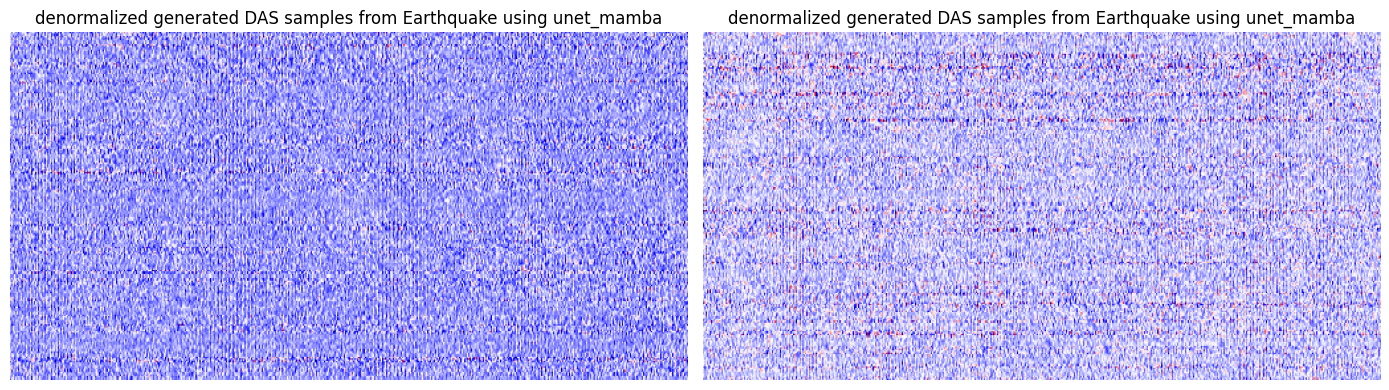

In [ ]:
from ddpm.utils.normalizer import denormalize
denormalized = denormalize(xt)
fig3, axes3 = plt.subplots(1, num_images, figsize = (7*num_images,4))
for i in range(num_images):
                axes3[i].imshow(denormalized[i,0].detach().cpu(), aspect="auto", cmap="seismic" ) 
                axes3[i].axis("off")
                axes3[i].set_title("denormalized generated DAS samples from Earthquake using unet_mamba")
plt.tight_layout()
plt.show()

In [20]:
percentiles=[50,60,99,99.9,99.99]
#normalized
x_test_e = next(iter(test_loader_mix))[0][:num_images].to(device)
#denomalized
x_test_e = denormalize(x_test_e).detach().cpu().numpy()
denormalized_tensor_e = denormalize(xt[:num_images])
denormalized_tensor_e= denormalized_tensor_e[:num_images].detach().cpu().numpy()

x_test_percentiles_e = np.percentile(np.abs(x_test_e).reshape(-1), percentiles)
denormalized_percentiles_e = np.percentile(np.abs(denormalized_tensor_e).reshape(-1), percentiles)

for i in range (len(percentiles)):
    print(
        f"{percentiles[i]}% |" f" real DAS Earthquakes: {x_test_percentiles_e[i]:.2f} |" f" generated DAS Earthquake {denormalized_percentiles_e[i]:.2f}"
    )

50% | real DAS Earthquakes: 24.81 | generated DAS Earthquake 27.94
60% | real DAS Earthquakes: 31.43 | generated DAS Earthquake 35.09
99% | real DAS Earthquakes: 1142.61 | generated DAS Earthquake 128.32
99.9% | real DAS Earthquakes: 3020.44 | generated DAS Earthquake 189.09
99.99% | real DAS Earthquakes: 4398.98 | generated DAS Earthquake 259.16


In [ ]:
import importlib
import ddpm.diffusion.ddim_sampler
importlib.reload(ddpm.diffusion.ddim_sampler)
from ddpm.diffusion.ddim_sampler import ddim_sample

In [22]:
generated_samples = ddim_sample(model =model_mb, num_samples=8, num_steps =50, device=device, eta=0.0)

In [25]:
import os
print(os.getpid())

1494894


In [26]:
from tqdm.auto import tqdm
num_samples = 1024
batch_size = 64

generated_samples = []
prog = tqdm(range(0, num_samples, batch_size), desc="DDIM Samples")
for s in prog:
    current_size = min(batch_size, num_samples-s)
    batch = ddim_sample(model = model_mb, num_samples=current_size, num_steps =50, device=device, eta=0.0)
    generated_samples.append(batch.cpu())
    #print(f"{min(s + batch_size, num_samples)}"f"/{num_samples}")
    prog.set_postfix(generated = min(s + batch_size, num_samples))
generated_samples = torch.cat(generated_samples, dim =0)  
print(generated_samples.shape)  

DDIM Samples:   0%|          | 0/16 [00:00<?, ?it/s]

torch.Size([1024, 1, 256, 512])


In [33]:
num_evl = generated_samples.shape[0]
real_samples = []
for batch, source in test_loader_mix:
    earthquake_batch = batch[source == 1]
    real_samples.append(earthquake_batch)
    if sum (x.shape[0] for x in real_samples) >= num_evl :
        break
real_samples = torch.cat(real_samples, dim=0)[:num_evl]    

In [ ]:
real_denorm = denormalize(real_samples).detach().cpu().numpy()
generated_denorm= denormalize(generated_samples).detach().cpu().numpy()

real_percentiles = np.percentile(np.abs(real_denorm).reshape(-1), percentiles)
generated_percentiles = np.percentile(np.abs(generated_denorm).reshape(-1), percentiles)

for i in range (len(percentiles)):
    print(
        f"{percentiles[i]}% |" f" real DAS Earthquakes: {real_percentiles[i]:.2f} |" f" generated DAS Earthquake {generated_percentiles[i]:.2f}"
    )

50% | real DAS Earthquakes: 42.92 | generated DAS Earthquake 29.86
60% | real DAS Earthquakes: 57.74 | generated DAS Earthquake 37.64
99% | real DAS Earthquakes: 1269.37 | generated DAS Earthquake 152.95
99.9% | real DAS Earthquakes: 2897.53 | generated DAS Earthquake 288.90
99.99% | real DAS Earthquakes: 4950.99 | generated DAS Earthquake 845.86


: 